In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import scienceplots

sys.path.append(str(Path("../python").resolve()))
from utils import *

plt.style.use(['science'])

# Match Overleaf: \documentclass[letterpaper, 11pt]{article} + \usepackage[scale=0.75]{geometry}
# US Letter width = 8.5 in -> \textwidth = 0.75 * 8.5 = 6.375 in
TEXTWIDTH = 6.375

mpl.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 11,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9.5,
})

In [2]:
t_present = (2 + fv0) / (3 * H_bar_0(fv0, H0))
t_near = 0.9999 * t_present

print("Present time t0:", t_present)
print("z(t0):", z_of_t(t_present, fv0, H0))
print("Effective H0 at z->0:", c * z_of_t(t_near, fv0, H0) / DA_timescape(t_near, t_present, fv0, H0))

Present time t0: 0.016485323383084574
z(t0): 2.220446049250313e-16
Effective H0 at z->0: 67.00762713613706


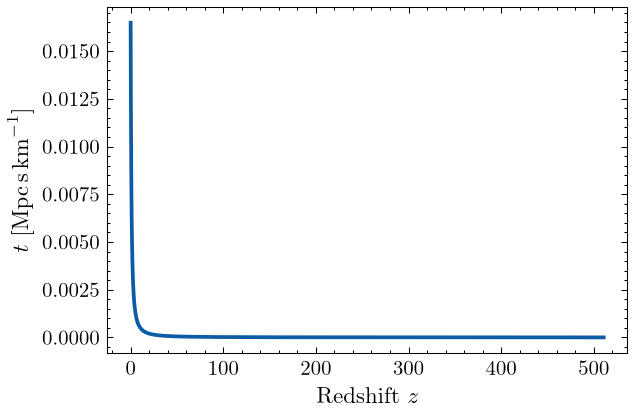

In [3]:
tt = np.geomspace(1e-4 * t_present, t_present, 1000)

fig, ax = plt.subplots(figsize=(0.7 * TEXTWIDTH, 3.0), dpi=150)
ax.plot(z_of_t(tt, fv0, H0), tt, lw=1.8)
ax.set_xlabel('Redshift $z$')
ax.set_ylabel('$t$ [$\mathrm{Mpc}\,\mathrm{s}\,\mathrm{km}^{-1}$]')
plt.tight_layout()
plt.show()

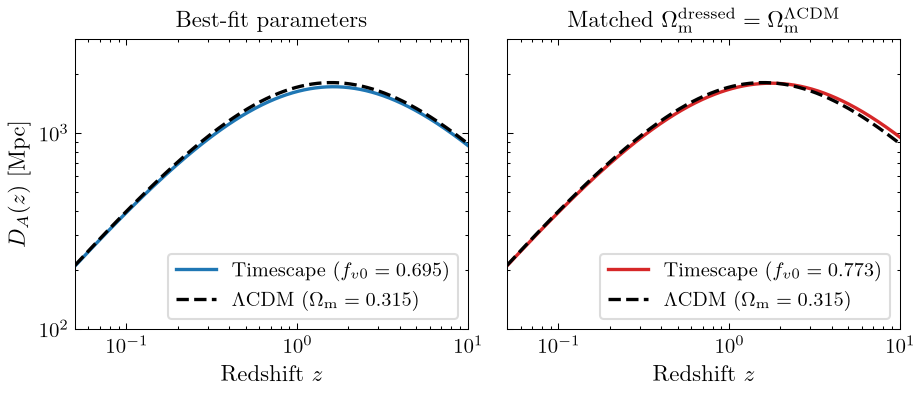

In [4]:
# --- 1. Reference LCDM curve ---
zz_lcdm = np.geomspace(5e-2, 10, 500)
DA_lcdm_ref = DA_lcdm(zz_lcdm, H0, Omm)

# --- 2. Left panel data: Best-fit Timescape constraint (fv0 = 0.695) ---
fv0_best = 0.695
t0_best = (2 + fv0_best) / (3 * H_bar_0(fv0_best, H0))
tt_best = np.geomspace(1e-4 * t0_best, t0_best * 0.9999, 1000)
z_ts_best = z_of_t(tt_best, fv0_best, H0)
DA_ts_best = DA_timescape(tt_best, t0_best, fv0_best, H0)

# --- 3. Right panel data: Dressed Omega_m matched to LCDM Omega_m ---
fv0_matched = fv0_from_dressed_Omm(Omm)
t0_matched = (2 + fv0_matched) / (3 * H_bar_0(fv0_matched, H0))
tt_matched = np.geomspace(1e-4 * t0_matched, t0_matched * 0.9999, 1000)
z_ts_matched = z_of_t(tt_matched, fv0_matched, H0)
DA_ts_matched = DA_timescape(tt_matched, t0_matched, fv0_matched, H0)

# --- 4. Side-by-side Figure (1:1 width with Overleaf \textwidth = 6.375 in) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(TEXTWIDTH, 2.85), sharey=True, dpi=150)

# Left panel: Best-fit parameters
ax1.loglog(z_ts_best, DA_ts_best, color='#1f77b4', lw=1.6,
           label=f'Timescape ($f_{{v0}}={fv0_best:.3f}$)')
ax1.loglog(zz_lcdm, DA_lcdm_ref, '--', color='black', lw=1.6,
           label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm:.3f}$)')
ax1.set_title('Best-fit parameters', pad=6)
ax1.set_xlabel('Redshift $z$')
ax1.set_ylabel('$D_A(z)$ [Mpc]')
ax1.set_xlim(5e-2, 10)
ax1.set_ylim(1e2, 3e3)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9,
           edgecolor='0.85', loc='lower right')

# Right panel: Matched dressed Omega_m = LCDM Omega_m
ax2.loglog(z_ts_matched, DA_ts_matched, color='#d62728', lw=1.6,
           label=f'Timescape ($f_{{v0}}={fv0_matched:.3f}$)')
ax2.loglog(zz_lcdm, DA_lcdm_ref, '--', color='black', lw=1.6,
           label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm:.3f}$)')
ax2.set_title(r'Matched $\Omega_{\rm m}^{\rm dressed} = \Omega_{\rm m}^{\Lambda\rm CDM}$', pad=6)
ax2.set_xlabel('Redshift $z$')
ax2.set_xlim(5e-2, 10)
ax2.legend(frameon=True, facecolor='white', framealpha=0.9,
           edgecolor='0.85', loc='lower right')

for ax in (ax1, ax2):
    ax.tick_params(which='both', direction='in', top=True, right=True)

plt.tight_layout()
fig.savefig('../imgs/DA_comparison.pdf', bbox_inches='tight')
plt.show()

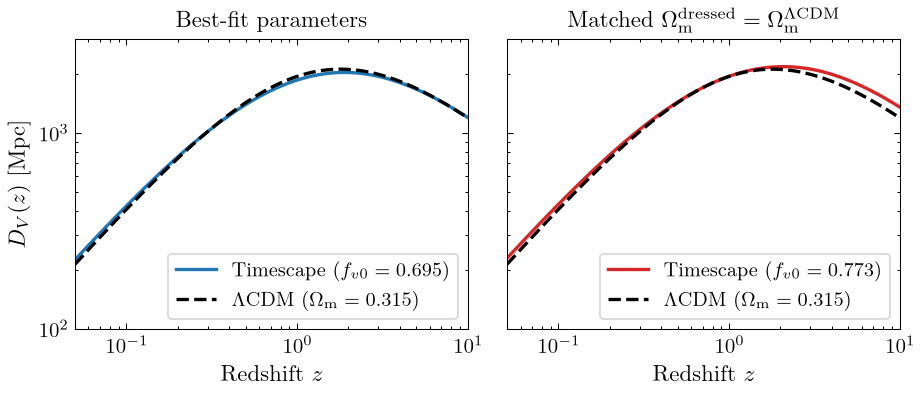

In [5]:
# --- 1. Reference LCDM curve ---
zz_lcdm = np.geomspace(5e-2, 10, 500)
DV_lcdm_ref = DV_lcdm(zz_lcdm, H0, Omm)

# --- 2. Left panel data: Best-fit Timescape constraint (fv0 = 0.695) ---
fv0_best = 0.695
t0_best = (2 + fv0_best) / (3 * H_bar_0(fv0_best, H0))
tt_best = np.geomspace(1e-4 * t0_best, t0_best * 0.9999, 1000)
z_ts_best = z_of_t(tt_best, fv0_best, H0)
DV_ts_best = DV_timescape(tt_best, t0_best, fv0_best, H0)

# --- 3. Right panel data: Dressed Omega_m matched to LCDM Omega_m ---
fv0_matched = fv0_from_dressed_Omm(Omm)
t0_matched = (2 + fv0_matched) / (3 * H_bar_0(fv0_matched, H0))
tt_matched = np.geomspace(1e-4 * t0_matched, t0_matched * 0.9999, 1000)
z_ts_matched = z_of_t(tt_matched, fv0_matched, H0)
DV_ts_matched = DV_timescape(tt_matched, t0_matched, fv0_matched, H0)

# --- 4. Side-by-side Figure (1:1 width with Overleaf \textwidth = 6.375 in) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(TEXTWIDTH, 2.85), sharey=True, dpi=150)

# Left panel: Best-fit parameters
ax1.loglog(z_ts_best, DV_ts_best, color='#1f77b4', lw=1.6,
           label=f'Timescape ($f_{{v0}}={fv0_best:.3f}$)')
ax1.loglog(zz_lcdm, DV_lcdm_ref, '--', color='black', lw=1.6,
           label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm:.3f}$)')
ax1.set_title('Best-fit parameters', pad=6)
ax1.set_xlabel('Redshift $z$')
ax1.set_ylabel('$D_V(z)$ [Mpc]')
ax1.set_xlim(5e-2, 10)
ax1.set_ylim(1e2, 3e3)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9,
           edgecolor='0.85', loc='lower right')

# Right panel: Matched dressed Omega_m = LCDM Omega_m
ax2.loglog(z_ts_matched, DV_ts_matched, color='#d62728', lw=1.6,
           label=f'Timescape ($f_{{v0}}={fv0_matched:.3f}$)')
ax2.loglog(zz_lcdm, DV_lcdm_ref, '--', color='black', lw=1.6,
           label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm:.3f}$)')
ax2.set_title(r'Matched $\Omega_{\rm m}^{\rm dressed} = \Omega_{\rm m}^{\Lambda\rm CDM}$', pad=6)
ax2.set_xlabel('Redshift $z$')
ax2.set_xlim(5e-2, 10)
ax2.legend(frameon=True, facecolor='white', framealpha=0.9,
           edgecolor='0.85', loc='lower right')

for ax in (ax1, ax2):
    ax.tick_params(which='both', direction='in', top=True, right=True)

plt.tight_layout()
fig.savefig('../imgs/DV_comparison.pdf', bbox_inches='tight')
plt.show()

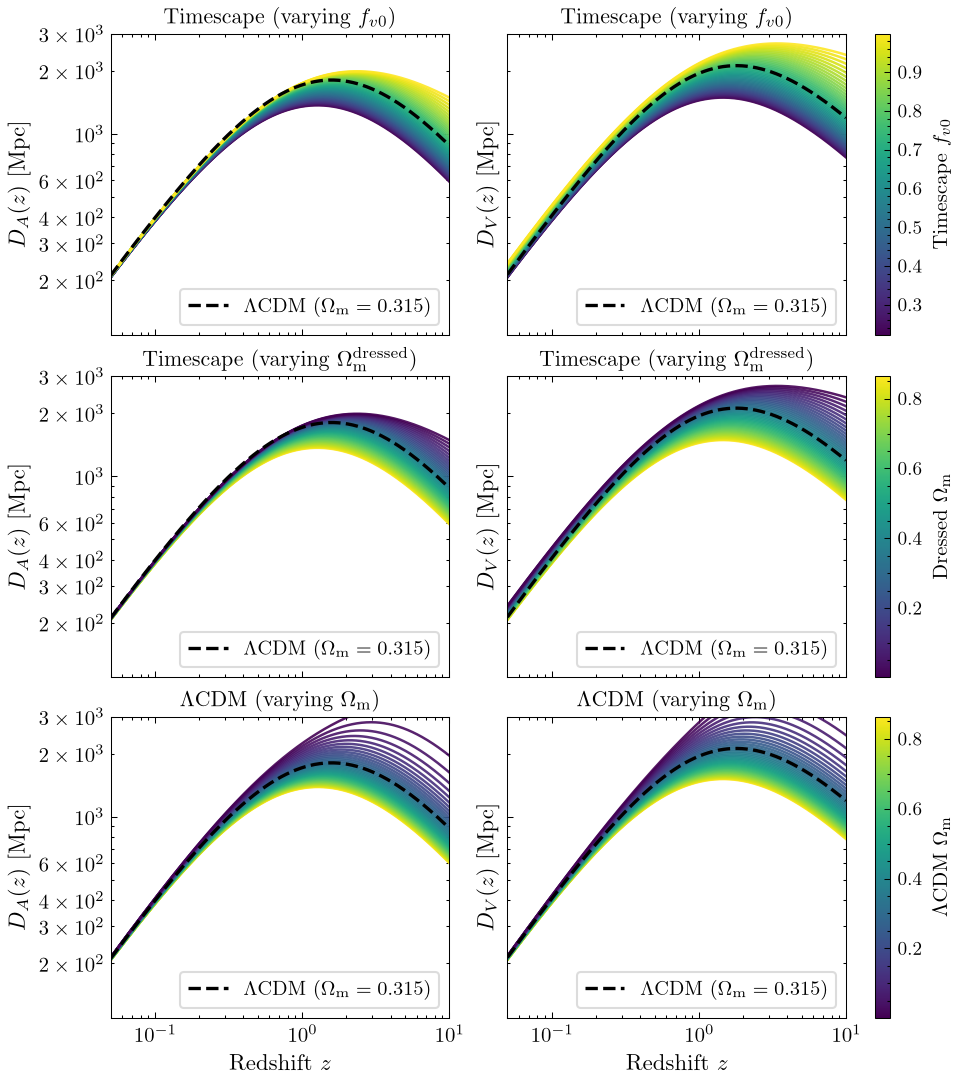

In [6]:
# --- 3x2 Figure: 3 rows (parameter variations) x 2 columns (Left: D_A, Right: D_V) ---
fv0_vals = np.linspace(fv0 * 0.32, 0.999, 50)
drsd_Omm_vals = dressed_Omm(fv0_vals)

cmap = plt.cm.viridis
norm_fv0 = mpl.colors.Normalize(vmin=fv0_vals.min(), vmax=fv0_vals.max())
norm_omm = mpl.colors.Normalize(vmin=drsd_Omm_vals.min(), vmax=drsd_Omm_vals.max())

# Precompute curves so we can plot both the 3x2 grid and individual 2-panel figures quickly
ts_curves = []
lcdm_curves = []
for fv, omm_d in zip(fv0_vals, drsd_Omm_vals):
    t0_val = (2 + fv) / (3 * H_bar_0(fv, H0))
    tt_val = np.geomspace(1e-4 * t0_val, t0_val * 0.9999, 1000)
    zz_ts = z_of_t(tt_val, fv, H0)
    da_ts = DA_timescape(tt_val, t0_val, fv, H0)
    dv_ts = DV_timescape(tt_val, t0_val, fv, H0)
    ts_curves.append((fv, omm_d, zz_ts, da_ts, dv_ts))

    da_l = DA_lcdm(zz_lcdm, H0, omm_d)
    dh_l = DH_lcdm(zz_lcdm, H0, omm_d)
    dv_l = np.cbrt(da_l**2 * dh_l * zz_lcdm)
    lcdm_curves.append((omm_d, da_l, dv_l))

# sharey=True across columns so y-tick numbers only appear on the left panel
fig, axes = plt.subplots(
    3, 2, figsize=(TEXTWIDTH, 7.2),
    sharex=True, sharey=True, dpi=150,
    layout='constrained'
)

for fv, omm_d, zz_ts, da_ts, dv_ts in ts_curves:
    # Row 0: Timescape varying fv0
    axes[0, 0].loglog(zz_ts, da_ts, color=cmap(norm_fv0(fv)), lw=1.2, alpha=0.9)
    axes[0, 1].loglog(zz_ts, dv_ts, color=cmap(norm_fv0(fv)), lw=1.2, alpha=0.9)

    # Row 1: Timescape varying dressed Omega_m
    axes[1, 0].loglog(zz_ts, da_ts, color=cmap(norm_omm(omm_d)), lw=1.2, alpha=0.9)
    axes[1, 1].loglog(zz_ts, dv_ts, color=cmap(norm_omm(omm_d)), lw=1.2, alpha=0.9)

for omm_d, da_l, dv_l in lcdm_curves:
    # Row 2: LCDM varying Omega_m
    axes[2, 0].loglog(zz_lcdm, da_l, color=cmap(norm_omm(omm_d)), lw=1.2, alpha=0.9)
    axes[2, 1].loglog(zz_lcdm, dv_l, color=cmap(norm_omm(omm_d)), lw=1.2, alpha=0.9)

row_titles = [
    r'Timescape (varying $f_{v0}$)',
    r'Timescape (varying $\Omega_{\rm m}^{\rm dressed}$)',
    r'$\Lambda$CDM (varying $\Omega_{\rm m}$)',
]

for r in range(3):
    # Left column: D_A(z)
    axes[r, 0].loglog(zz_lcdm, DA_lcdm_ref, color='black', ls='--', lw=1.6, zorder=10,
                      label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm}$)')
    axes[r, 0].set_ylabel('$D_A(z)$ [Mpc]')
    axes[r, 0].set_title(row_titles[r], fontsize=10.5, pad=5)

    # Right column: D_V(z) (sharey hides tick numbers on left spine of right panel)
    axes[r, 1].loglog(zz_lcdm, DV_lcdm_ref, color='black', ls='--', lw=1.6, zorder=10,
                      label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm}$)')
    axes[r, 1].set_ylabel('$D_V(z)$ [Mpc]')
    axes[r, 1].set_title(row_titles[r], fontsize=10.5, pad=5)
    axes[r, 1].tick_params(which='both', labelleft=False)

    for c in range(2):
        axes[r, c].set_xlim(5e-2, 10)
        axes[r, c].set_ylim(1.1e2, 3e3)
        axes[r, c].tick_params(which='both', direction='in', top=True, right=True)
        axes[r, c].legend(frameon=True, facecolor='white', framealpha=0.9,
                          edgecolor='0.85', loc='lower right')
        if r == 2:
            axes[r, c].set_xlabel('Redshift $z$')

# Colorbars attached to each row [axes[r, 0], axes[r, 1]] so both panels stay equal width
cbar_configs = [
    (norm_fv0, r'Timescape $f_{v0}$'),
    (norm_omm, r'Dressed $\Omega_{\rm m}$'),
    (norm_omm, r'$\Lambda$CDM $\Omega_{\rm m}$'),
]
for r, (norm_r, label_r) in enumerate(cbar_configs):
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm_r)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=axes[r, :], pad=0.02, aspect=20)
    cb.set_label(label_r, fontsize=10, labelpad=5)
    cb.ax.tick_params(labelsize=9)

fig.savefig('../imgs/DA_DV_pars_3x2.pdf', bbox_inches='tight')
plt.show()

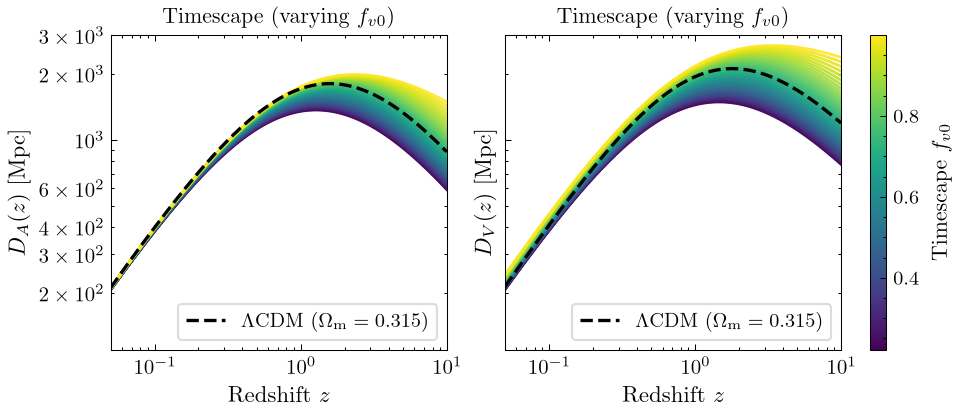

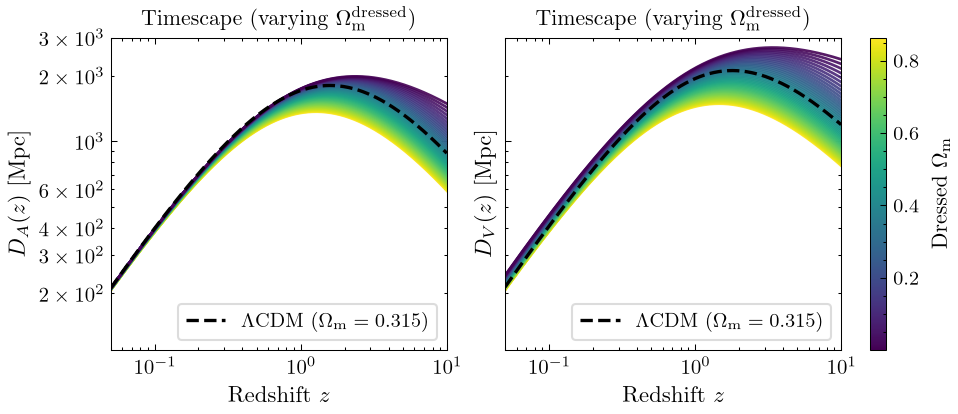

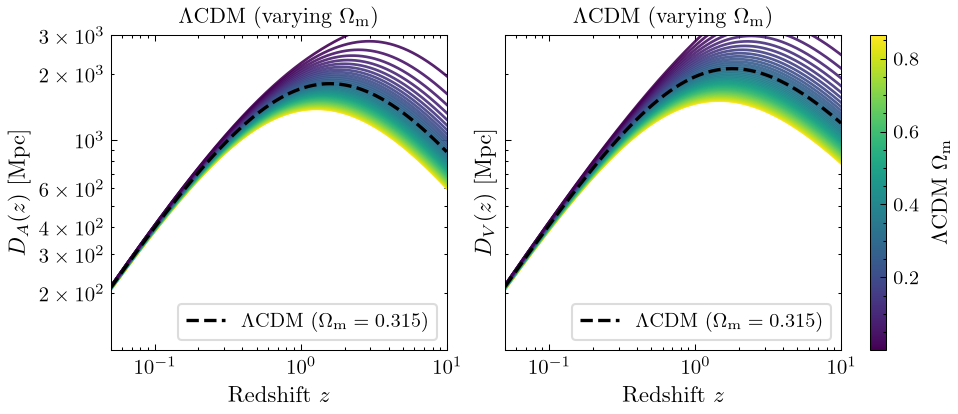

In [7]:
# --- Individual 2-panel figures (Left: D_A, Right: D_V) for each of the 3 parameter variations ---
def plot_two_panel_variation(curves, is_timescape, norm, cbar_label, title_str, filename):
    fig, (ax_da, ax_dv) = plt.subplots(
        1, 2, figsize=(TEXTWIDTH, 2.75),
        sharey=True, dpi=150,
        layout='constrained'
    )

    if is_timescape:
        for fv, omm_d, zz_ts, da_ts, dv_ts in curves:
            val = fv if norm is norm_fv0 else omm_d
            ax_da.loglog(zz_ts, da_ts, color=cmap(norm(val)), lw=1.3, alpha=0.9)
            ax_dv.loglog(zz_ts, dv_ts, color=cmap(norm(val)), lw=1.3, alpha=0.9)
    else:
        for omm_d, da_l, dv_l in curves:
            ax_da.loglog(zz_lcdm, da_l, color=cmap(norm(omm_d)), lw=1.3, alpha=0.9)
            ax_dv.loglog(zz_lcdm, dv_l, color=cmap(norm(omm_d)), lw=1.3, alpha=0.9)

    ax_da.loglog(zz_lcdm, DA_lcdm_ref, color='black', ls='--', lw=1.6, zorder=10,
                 label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm}$)')
    ax_dv.loglog(zz_lcdm, DV_lcdm_ref, color='black', ls='--', lw=1.6, zorder=10,
                 label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm}$)')

    ax_da.set_ylabel('$D_A(z)$ [Mpc]')
    ax_dv.set_ylabel('$D_V(z)$ [Mpc]')
    ax_dv.tick_params(which='both', labelleft=False)

    for ax in (ax_da, ax_dv):
        ax.set_xlim(5e-2, 10)
        ax.set_ylim(1.1e2, 3e3)
        ax.set_xlabel('Redshift $z$')
        ax.set_title(title_str, fontsize=10.5, pad=6)
        ax.tick_params(which='both', direction='in', top=True, right=True)
        ax.legend(frameon=True, facecolor='white', framealpha=0.9,
                  edgecolor='0.85', loc='lower right')

    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=[ax_da, ax_dv], pad=0.02, aspect=20)
    cb.set_label(cbar_label, fontsize=10.5, labelpad=6)
    cb.ax.tick_params(labelsize=9.5)

    fig.savefig(f'../imgs/{filename}', bbox_inches='tight')
    plt.show()

# 1. Timescape varying fv0
plot_two_panel_variation(
    ts_curves, True, norm_fv0,
    r'Timescape $f_{v0}$', r'Timescape (varying $f_{v0}$)',
    'DA_DV_pars_fv0.pdf'
)

# 2. Timescape varying dressed Omega_m
plot_two_panel_variation(
    ts_curves, True, norm_omm,
    r'Dressed $\Omega_{\rm m}$', r'Timescape (varying $\Omega_{\rm m}^{\rm dressed}$)',
    'DA_DV_pars_ts_omm.pdf'
)

# 3. LCDM varying Omega_m
plot_two_panel_variation(
    lcdm_curves, False, norm_omm,
    r'$\Lambda$CDM $\Omega_{\rm m}$', r'$\Lambda$CDM (varying $\Omega_{\rm m}$)',
    'DA_DV_pars_lcdm_omm.pdf'
)